# Churn-Risk Prediction — EDA & Preprocessing

Dataset: `data_ecommerce_customer_churn.csv`

Goal: Predict customer `Churn` using transactional/customer attributes.

> Raw data only. Not transformed data.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import warnings
warnings.filterwarnings('ignore')

In [23]:
df = pd.read_csv('d:/CDP -FYP/data_prep/raw/e-commerce-customer-churn/data_ecommerce_customer_churn.csv')
df.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0


In [8]:
print('Shape:', df.shape)
print()
df.info()

Shape: (3941, 11)

<class 'pandas.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3747 non-null   float64
 1   WarehouseToHome           3772 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   str    
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   str    
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3728 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), str(2)
memory usage: 338.8 KB


In [9]:
df.describe(include='all')

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
count,3747.000000,3772.000000,3941.000000,3941,3941.000000,3941,3941.000000,3941.000000,3728.000000,3941.000000,3941.000000
unique,NaN,NaN,NaN,6,NaN,3,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,Laptop & Accessory,NaN,Married,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,1458,NaN,2055,NaN,NaN,NaN,NaN,NaN
mean,10.081398,15.650583,3.679269,NaN,3.088302,NaN,4.237757,0.282416,4.531652,176.707419,0.171023
std,8.498864,8.452301,1.013938,NaN,1.381832,NaN,2.626699,0.450232,3.667648,48.791784,0.376576
min,0.000000,5.000000,1.000000,NaN,1.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,9.000000,3.000000,NaN,2.000000,NaN,2.000000,0.000000,2.000000,145.700000,0.000000
50%,9.000000,14.000000,4.000000,NaN,3.000000,NaN,3.000000,0.000000,3.000000,163.340000,0.000000
75%,16.000000,21.000000,4.000000,NaN,4.000000,NaN,6.000000,1.000000,7.000000,195.250000,0.000000


In [10]:
df.isnull().sum()

Tenure                      194
WarehouseToHome             169
NumberOfDeviceRegistered      0
PreferedOrderCat              0
SatisfactionScore             0
MaritalStatus                 0
NumberOfAddress               0
Complain                      0
DaySinceLastOrder           213
CashbackAmount                0
Churn                         0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(671)

In [12]:
df['Churn'].value_counts()
df['Churn'].value_counts(normalize=True)

Churn
0    0.828977
1    0.171023
Name: proportion, dtype: float64

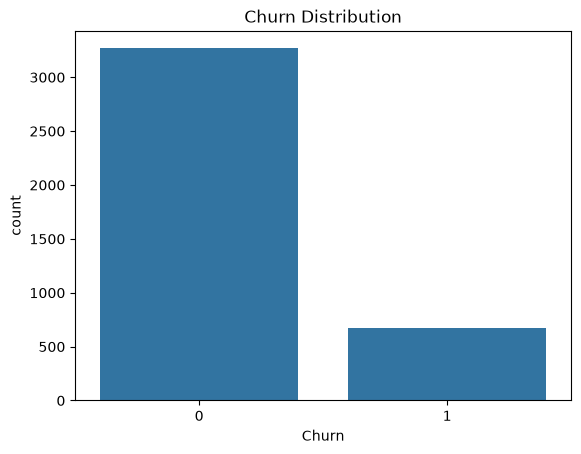

In [14]:
sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

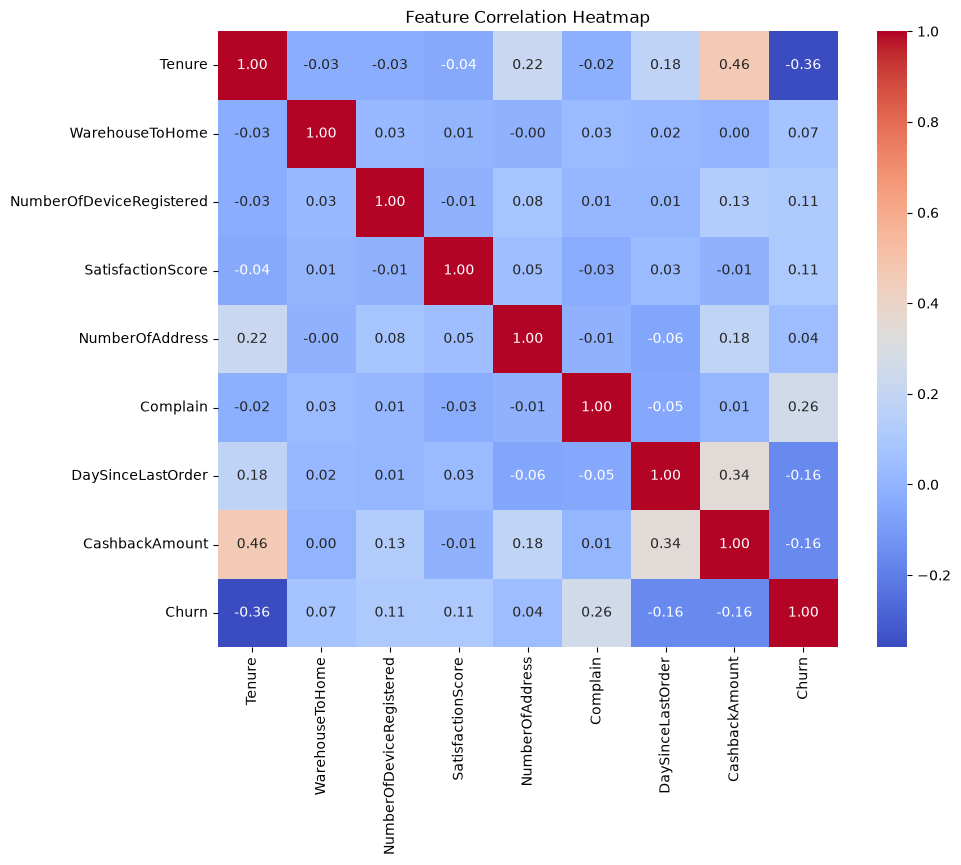

In [15]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

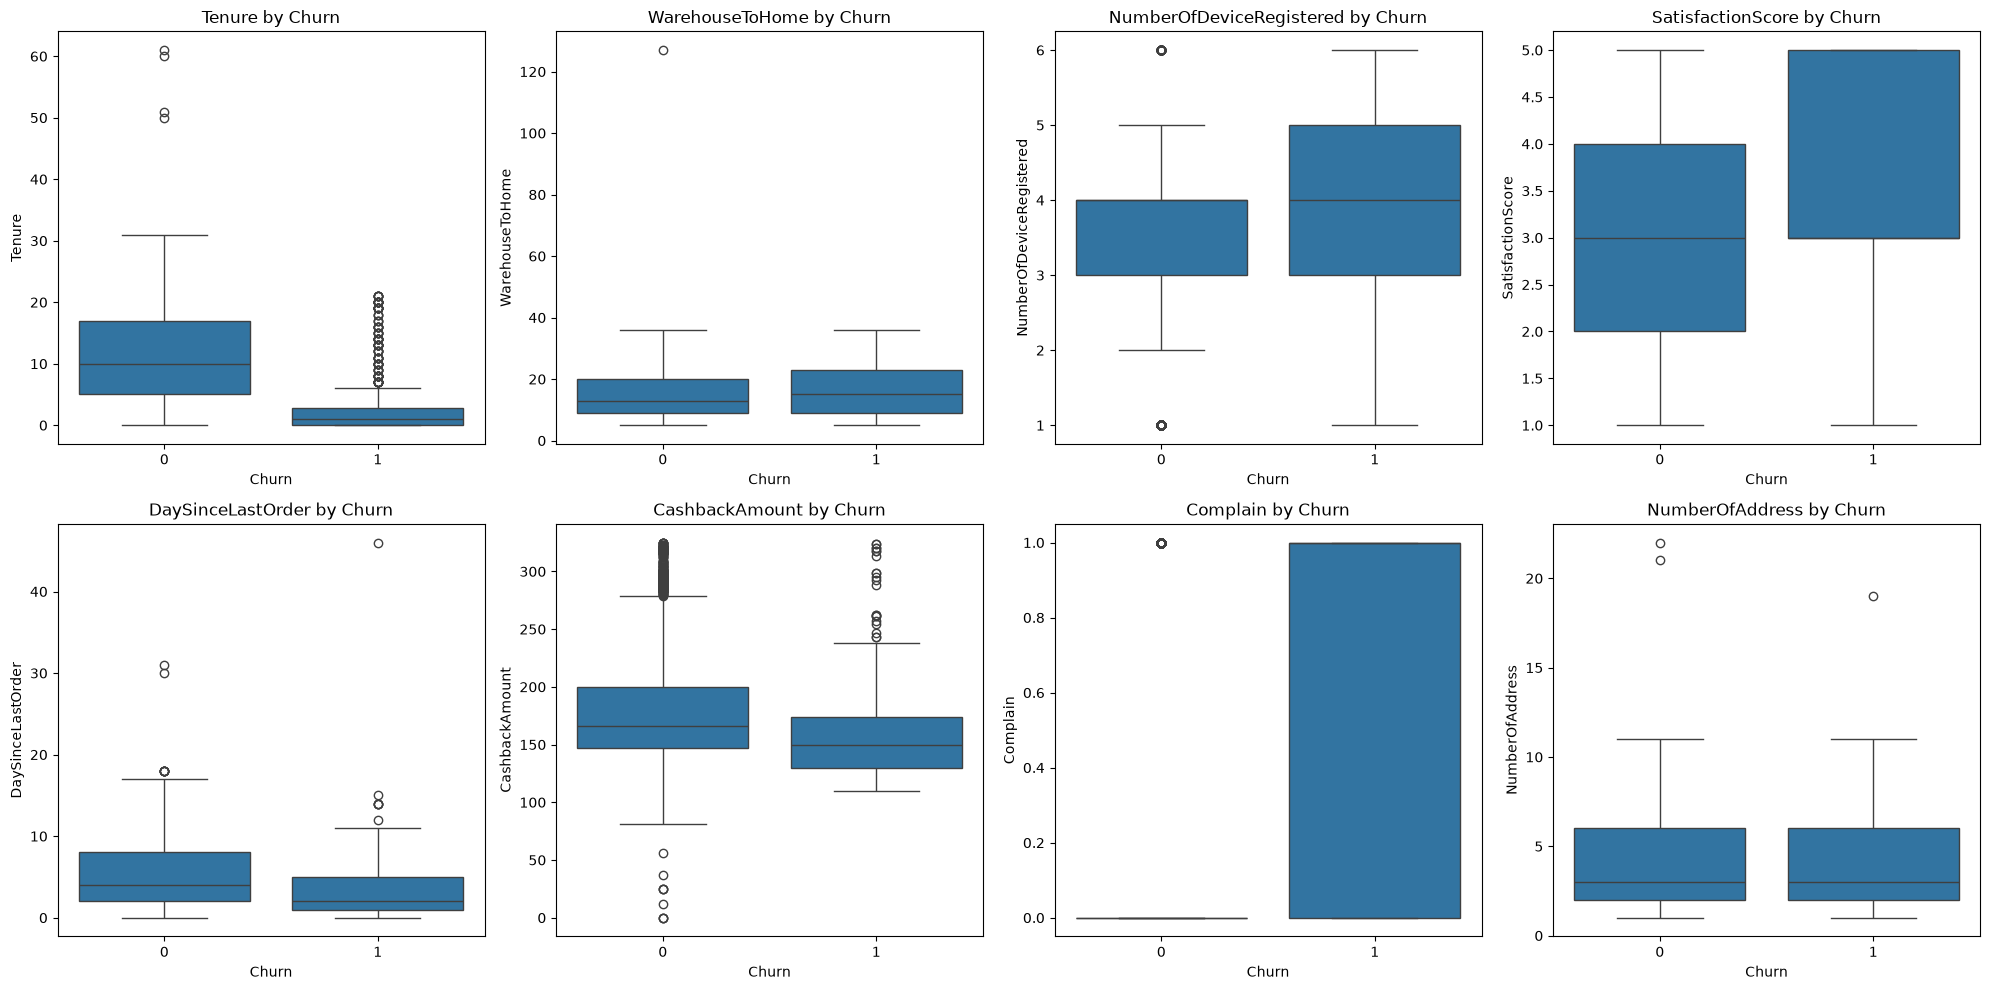

In [16]:
features = ['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'DaySinceLastOrder', 'CashbackAmount', 'Complain', 'NumberOfAddress']
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for i, col in enumerate(features):
    if col in df.columns:
        sns.boxplot(x='Churn', y=col, data=df, ax=axes[i//4, i%4])
        axes[i//4, i%4].set_title(f'{col} by Churn')
plt.tight_layout()
plt.show()

In [17]:
cols_to_drop = ['MaritalStatus', 'NumberOfAddress', 'PreferedOrderCat']
if 'CustomerID' in df.columns:
    cols_to_drop.append('CustomerID')

df_clean = df.drop(columns=cols_to_drop)
df_clean.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,3,0,7.0,143.32,0
1,7.0,25.0,4,1,0,7.0,129.29,0
2,27.0,13.0,3,1,0,7.0,168.54,0
3,20.0,25.0,4,3,0,NaN,230.27,0
4,30.0,15.0,4,4,0,8.0,322.17,0


In [18]:
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
if 'Churn' in numeric_cols:
    numeric_cols.remove('Churn')

imputer = SimpleImputer(strategy='median')
df_clean[numeric_cols] = imputer.fit_transform(df_clean[numeric_cols])

cat_cols = df_clean.select_dtypes(include=['object']).columns.tolist()
if cat_cols:
    cat_imputer = SimpleImputer(strategy='most_frequent')
    df_clean[cat_cols] = cat_imputer.fit_transform(df_clean[cat_cols])

print('Missing after imputation:', df_clean.isnull().sum().sum())

Missing after imputation: 0


In [19]:
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
after = len(df_clean)
print(f'Removed {before - after} duplicate rows')

Removed 926 duplicate rows


In [20]:
le = LabelEncoder()
for col in cat_cols:
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))
df_clean.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4.0,3.0,0.0,7.0,143.32,0
1,7.0,25.0,4.0,1.0,0.0,7.0,129.29,0
2,27.0,13.0,3.0,1.0,0.0,7.0,168.54,0
3,20.0,25.0,4.0,3.0,0.0,3.0,230.27,0
4,30.0,15.0,4.0,4.0,0.0,8.0,322.17,0


In [26]:
if 'DaySinceLastOrder' in df_clean.columns:
    df_model = df_clean.drop(columns=['DaySinceLastOrder'])
else:
    df_model = df_clean.copy()

print('Final model columns:', df_model.columns.tolist())

Final model columns: ['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'Complain', 'CashbackAmount', 'Churn']


In [27]:
scaler = StandardScaler()
num_cols = [c for c in df_model.select_dtypes(include=[np.number]).columns if c != 'Churn']
df_model[num_cols] = scaler.fit_transform(df_model[num_cols])
df_model.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,Complain,CashbackAmount,Churn
0,0.584714,1.630296,0.321716,0.032452,-0.627612,-0.684871,0
1,-0.365131,1.152730,0.321716,-1.385566,-0.627612,-0.970599,0
2,2.009481,-0.279966,-0.652153,-1.385566,-0.627612,-0.171254,0
3,1.178367,1.152730,0.321716,0.032452,-0.627612,1.085906,0
4,2.365673,-0.041183,0.321716,0.741461,-0.627612,2.957493,0


In [28]:
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'Train churn rate: {y_train.mean():.2f}, Test churn rate: {y_test.mean():.2f}')

Train: (2412, 6), Test: (603, 6)
Train churn rate: 0.16, Test churn rate: 0.16


In [29]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

In [30]:
lr = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
lr.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [31]:
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

print('=== Random Forest ===')
print(classification_report(y_test, rf_pred))
print('ROC-AUC:', round(roc_auc_score(y_test, rf_prob), 4))

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.94      0.92      0.93       505
           1       0.61      0.68      0.65        98

    accuracy                           0.88       603
   macro avg       0.78      0.80      0.79       603
weighted avg       0.88      0.88      0.88       603

ROC-AUC: 0.905


In [32]:
lr_pred = lr.predict(X_test)
lr_prob = lr.predict_proba(X_test)[:, 1]

print('=== Logistic Regression ===')
print(classification_report(y_test, lr_pred))
print('ROC-AUC:', round(roc_auc_score(y_test, lr_prob), 4))

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.94      0.75      0.84       505
           1       0.37      0.77      0.50        98

    accuracy                           0.75       603
   macro avg       0.66      0.76      0.67       603
weighted avg       0.85      0.75      0.78       603

ROC-AUC: 0.8468


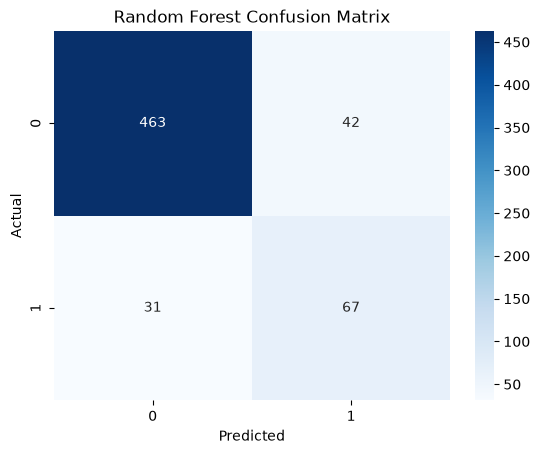

In [33]:
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

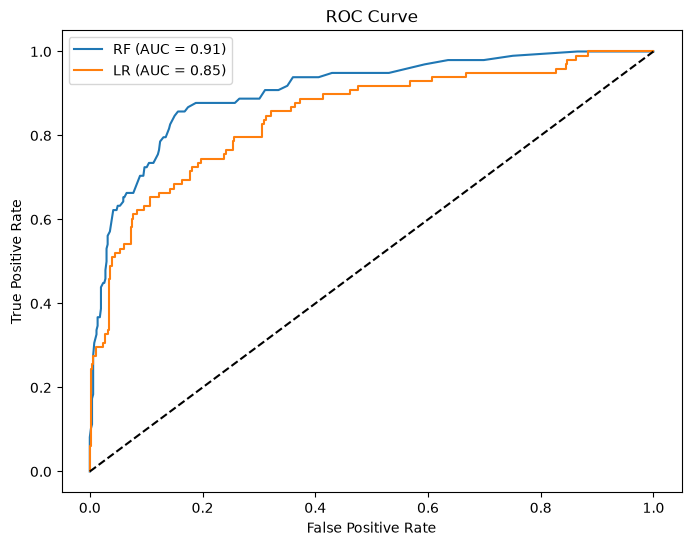

In [34]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, label=f'RF (AUC = {roc_auc_score(y_test, rf_prob):.2f})')
plt.plot(fpr_lr, tpr_lr, label=f'LR (AUC = {roc_auc_score(y_test, lr_prob):.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

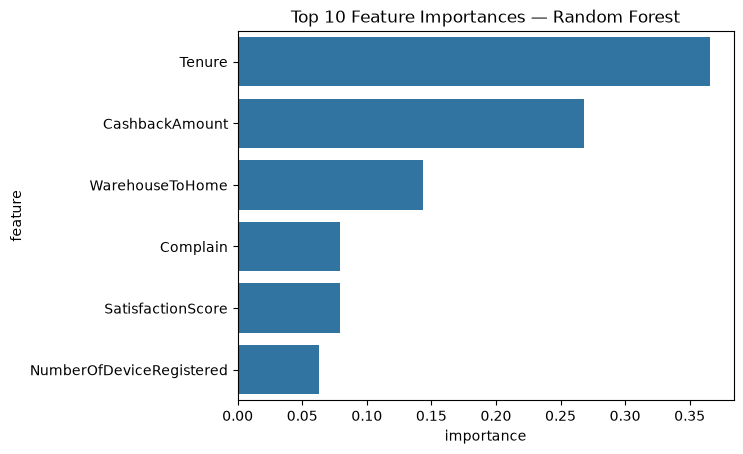

,feature,importance
0,Tenure,0.365779
5,CashbackAmount,0.268275
1,WarehouseToHome,0.143722
4,Complain,0.079462
3,SatisfactionScore,0.079430
2,NumberOfDeviceRegistered,0.063332


In [35]:
feat_imp = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
feat_imp = feat_imp.sort_values('importance', ascending=False)

sns.barplot(x='importance', y='feature', data=feat_imp.head(10))
plt.title('Top 10 Feature Importances — Random Forest')
plt.show()
feat_imp

In [36]:
import joblib, os

rf_auc = roc_auc_score(y_test, rf_prob)
lr_auc = roc_auc_score(y_test, lr_prob)

best_model = rf if rf_auc >= lr_auc else lr
best_name  = 'Random Forest' if rf_auc >= lr_auc else 'Logistic Regression'
best_auc   = max(rf_auc, lr_auc)

print(f'Selected model: {best_name} (ROC-AUC = {best_auc:.4f})')


Selected model: Random Forest (ROC-AUC = 0.9050)


In [ ]:
os.makedirs('d:/CDP -FYP/backend/ml_models', exist_ok=True)
joblib.dump(best_model, 'd:/CDP -FYP/backend/ml_models/churn_model.pkl')

['d:/CDP -FYP/backend/ml_models/churn_model.pkl']